# Diphoton events with a b-tagged jet: ATLAS Open Data

This notebook downloads and gives a first look at a small skim of the **ATLAS Open Data** 13 TeV diphoton (`GamGam`) sample:
the 2015+2016 collision data and all Standard Model H(125)→γγ simulation samples, reduced to events with **at least one b-tagged jet**.

**How to use it:** run the cells from top to bottom (Shift+Enter). The download cell fetches about 370 MB into `~/hyy_bjet`; running it again skips files you already have.

Web page with the same information: <https://portal.nersc.gov/cfs/atlas/haichenwang/physics129/>

*Derived from public ATLAS Open Data (opendata.atlas.cern). Not an ATLAS Collaboration result.*

## What is available

| | |
|---|---|
| Data files (2015 + 2016, 36.1 fb⁻¹) | 16 |
| Data events kept | 880,440 of 36,564,144 (2.41%) |
| H→γγ simulation files | 26 (9 nominal, 17 alternative generators) |
| Simulated events kept | 210,353 of 2,200,495 |
| Total download | 389 MB, 42 files |

**Selection.** An event is kept if at least one jet has `jet_btag_quantile >= 4`, i.e. passes the 70% efficiency b-tagging working point. The ntuple jets already have pT > 20 GeV and |η| < 2.5. Nothing else is cut, and all 118 branches of the tree `analysis` are kept.

**Expected SM Higgs signal** (nominal samples, weighted to 36.1 fb⁻¹, no further cuts):

| Production mode | Before b-jet cut | After b-jet cut | Kept |
|---|---|---|---|
| ggH | 1877.6 | 21.88 | 1.2% |
| VBF | 148.6 | 2.12 | 1.4% |
| WH | 47.2 | 0.92 | 2.0% |
| ZH + ggZH | 32.0 | 3.17 | 9.9% |
| ttH | 22.9 | 14.38 | 62.9% |
| tH (tHjb + tWH) | 0.8 | 0.38 | 48.3% |
| **Total** | **2129.1** | **42.9** | **2.0%** |

The b-jet requirement removes about 99% of gluon-fusion Higgs events but keeps about two thirds of ttH, which is why it is the starting point for studying Higgs production with top quarks.

## 1. Set up and download

In [1]:
# Install the two ROOT-file readers if this environment does not have them yet.
import importlib.util, subprocess, sys
missing = [p for p in ("uproot", "awkward") if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("ready")

ready


In [2]:
import json, os, urllib.request

BASE = "https://portal.nersc.gov/cfs/atlas/haichenwang/physics129"
DEST = "~/hyy_bjet"                               # change this to download somewhere else

manifest = json.load(urllib.request.urlopen(f"{BASE}/manifest.json"))
new = 0
for f in manifest["files"]:                       # f["file"] is e.g. "MC/....1bjet.root"
    path = os.path.join(os.path.expanduser(DEST), f["file"])
    if os.path.exists(path) and os.path.getsize(path) == f["bytes_out"]:
        continue                                  # already downloaded
    os.makedirs(os.path.dirname(path), exist_ok=True)
    urllib.request.urlretrieve(f"{BASE}/{f['file']}", path + ".part")
    os.replace(path + ".part", path)
    assert os.path.getsize(path) == f["bytes_out"], f"size mismatch: {path}"
    new += 1
print(f"{len(manifest['files'])} files in {DEST}: {new} downloaded now, {len(manifest['files']) - new} already there")

42 files in ~/hyy_bjet: 0 downloaded now, 42 already there


## 2. What is in each file

In [3]:
import pandas as pd
pd.set_option("display.max_rows", 100)

files = pd.DataFrame(manifest["files"])
files["kept_%"] = (100 * files["fraction"]).round(2)
files["MB"] = (files["bytes_out"] / 1e6).round(1)

print("Data")
display(files[files.role == "data"][["generator", "entries_in", "entries_out", "kept_%", "MB"]]
        .rename(columns={"generator": "period"}).reset_index(drop=True))
print("Simulation (expected events at 36.1 fb^-1 before and after the b-jet cut)")
display(files[files.role != "data"][["dsid", "mode", "generator", "role", "entries_out", "kept_%",
                                     "yield_in", "yield_out"]].round(3).reset_index(drop=True))

Data


,period,entries_in,entries_out,kept_%,MB
0,data15 periodD,63195,1581,2.50,0.5
1,data15 periodE,529228,12929,2.44,3.9
2,data15 periodF,352365,8473,2.40,2.5
3,data15 periodG,826534,20298,2.46,6.1
4,data15 periodH,279169,6937,2.48,2.1
5,data15 periodJ,1527804,37550,2.46,11.3
6,data16 periodA,611028,15575,2.55,4.7
7,data16 periodB,1892618,46026,2.43,13.9
8,data16 periodC,2368135,57581,2.43,17.4
9,data16 periodD,4723215,114676,2.43,34.7


Simulation (expected events at 36.1 fb^-1 before and after the b-jet cut)


,dsid,mode,generator,role,entries_out,kept_%,yield_in,yield_out
0,343981,ggH,Powheg+Pythia8 NNLOPS,nominal,1092,1.16,1877.643,21.883
1,346214,VBF,Powheg+Pythia8,nominal,549,1.43,148.579,2.121
2,345317,W−H,Powheg+Pythia8 MiNLO,nominal,1996,2.06,19.551,0.404
3,345318,W+H,Powheg+Pythia8 MiNLO,nominal,900,1.88,27.694,0.520
4,345319,ZH,Powheg+Pythia8 MiNLO,nominal,3258,9.60,26.670,2.564
5,345061,ggZH,Powheg+Pythia8,nominal,2419,11.37,5.347,0.608
6,346189,ttH,MG5_aMC@NLO+Pythia8,nominal,18690,63.16,22.860,14.381
7,346188,tHjb,MG5_aMC@NLO+Pythia8,nominal,9140,51.18,0.109,0.056
8,346486,tWH,MG5_aMC@NLO+Pythia8,nominal,8700,51.72,0.687,0.329
9,346525,ttH,Powheg+Pythia8,alternative,41874,64.11,22.636,14.566


## 3. First look: the diphoton mass

Read the photons, select a simple H→γγ-like diphoton pair and compare data with the expected SM Higgs signal. Reading all files takes about a minute.

In [4]:
import glob
import awkward as ak
import numpy as np
import uproot

LUMI_PB = 36100.0                                 # 36.1 fb^-1 in pb^-1
FILES = os.path.expanduser(DEST)
NOMINAL = {"ggH": ["343981"], "VBF": ["346214"], "WH": ["345317", "345318"], "ZH": ["345319", "345061"],
           "ttH": ["346189"], "tH": ["346188", "346486"]}

def diphoton_mass(path, is_mc):
    """m_yy and event weight for events with two tight, isolated photons (a simple H->yy-like selection)."""
    branches = ["photon_pt", "photon_eta", "photon_phi", "photon_e", "photon_isTightID", "photon_isTightIso"]
    if is_mc:
        branches += ["mcWeight", "xsec", "kfac", "filteff", "sum_of_weights"]
    ev = uproot.open(path)["analysis"].arrays(branches)
    aeta = abs(ev.photon_eta)
    good = ((ev.photon_pt > 25) & (aeta < 2.37) & ~((aeta > 1.37) & (aeta < 1.52))
            & ev.photon_isTightID & ev.photon_isTightIso)
    order = ak.argsort(ev.photon_pt[good], ascending=False)
    ph = {k: ev[f"photon_{k}"][good][order] for k in ("pt", "eta", "phi", "e")}
    two = ak.num(ph["pt"]) >= 2
    pt, eta, phi, e = (np.asarray(ak.to_regular(ph[k][two][:, :2])) for k in ("pt", "eta", "phi", "e"))
    px, py, pz = (pt * np.cos(phi)).sum(1), (pt * np.sin(phi)).sum(1), (pt * np.sinh(eta)).sum(1)
    m = np.sqrt(np.maximum(e.sum(1) ** 2 - px**2 - py**2 - pz**2, 0))
    w = np.ones(len(m))
    if is_mc:
        s = ev[two]
        w = np.asarray(s.mcWeight * s.xsec * s.kfac * s.filteff * LUMI_PB / s.sum_of_weights)
    with np.errstate(divide="ignore", invalid="ignore"):
        keep = (pt[:, 0] / m > 0.35) & (pt[:, 1] / m > 0.25) & (m > 105) & (m < 160)
    return m[keep], w[keep]

data_m = np.concatenate([diphoton_mass(p, False)[0] for p in sorted(glob.glob(f"{FILES}/data/*.root"))])
signal = {}
for mode, dsids in NOMINAL.items():
    parts = [diphoton_mass(glob.glob(f"{FILES}/MC/*_mc_{d}.*.root")[0], True) for d in dsids]
    signal[mode] = (np.concatenate([p[0] for p in parts]), np.concatenate([p[1] for p in parts]))

print(f"data events, 105 < m_yy < 160 GeV: {len(data_m):,}")
for mode, (m, w) in signal.items():
    print(f"expected {mode:4s}: {w.sum():6.2f} events")
print(f"expected total SM H->yy: {sum(w.sum() for _, w in signal.values()):.2f} events")

data events, 105 < m_yy < 160 GeV: 3,252
expected ggH :  12.46 events
expected VBF :   1.28 events
expected WH  :   0.49 events
expected ZH  :   1.77 events
expected ttH :   6.61 events
expected tH  :   0.19 events
expected total SM H->yy: 22.81 events


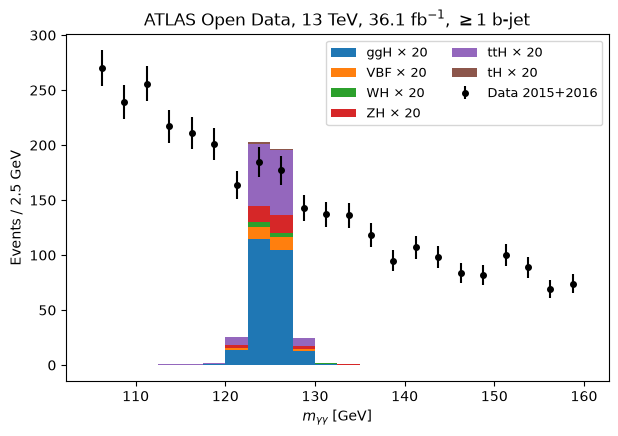

In [5]:
import matplotlib.pyplot as plt

SCALE = 20                                        # signal is scaled up so it is visible
bins = np.arange(105, 161, 2.5)
centres = 0.5 * (bins[1:] + bins[:-1])
counts, _ = np.histogram(data_m, bins)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist([signal[k][0] for k in signal], bins, weights=[SCALE * signal[k][1] for k in signal],
        stacked=True, label=[f"{k} × {SCALE}" for k in signal])
ax.errorbar(centres, counts, yerr=np.sqrt(counts), fmt="ko", ms=4, label="Data 2015+2016")
ax.set_xlabel(r"$m_{\gamma\gamma}$ [GeV]")
ax.set_ylabel(f"Events / {bins[1] - bins[0]:g} GeV")
ax.set_title(r"ATLAS Open Data, 13 TeV, 36.1 fb$^{-1}$, $\geq$1 b-jet")
ax.legend(ncol=2, fontsize=9)
plt.show()

## Good to know

- **Event weight for simulation:** `mcWeight × xsec × kfac × filteff × 36100 / sum_of_weights` gives events at 36.1 fb⁻¹. The normalisation branches hold full-sample values, so this is correct for the skimmed files. Data events have weight 1.
- **Three alternative samples (500554, 500555, 506813)** have normalisation branches that leave out BR(H→γγ). Multiply their weights by 0.00227. The nominal samples used above are not affected.
- **Use either nominal or alternative samples for a process, not both.** The alternatives (Herwig7 showers, MG5_aMC@NLO) are for modelling comparisons.
- **Background:** the γγ continuum is not simulated here. It is usually modelled with a smooth fit to the data sidebands, away from 125 GeV.
- **Scale factors** for photons, pile-up, JVT and b-tagging are in the `ScaleFactor_*` branches if you want to include them.
- Selection in the first-look plot: two photons with pT > 25 GeV, |η| < 2.37 outside 1.37–1.52, tight ID and isolation, pT/m_γγ > 0.35 and 0.25. These are a simple choice for illustration, not a prescription.

## Optional: the original, unskimmed files

The skim was made from 42 files on the CERN Open Data portal (10.75 GB in total, 9.86 GB of it data). To download them, run this in a cell or a terminal:

```
!curl -sO https://portal.nersc.gov/cfs/atlas/haichenwang/physics129/download_gamgam_original.py
!python3 download_gamgam_original.py --list --set all          # see what is available
!python3 download_gamgam_original.py --set nominal-mc          # 9 nominal Higgs samples, 0.17 GB
!python3 download_gamgam_original.py --set data --match data15 # 2015 data only, 0.96 GB
```

Sets: `nominal-mc` (default), `alt-mc`, `mc`, `data`, `all`. Files go to `~/hyy_original`; running again resumes and skips finished files. The full data may not fit in your DataHub storage, so pick periods with `--match`, or read files over the network with `uproot.open("https://opendata.cern.ch/eos/opendata/atlas/rucio/opendata/<file name>")`.